# Thermal boundary conditions (Sec. 4.3)

Generates `figures/thermal_creep_shared_cbar.pdf` from `results/3_thermal_creep/`.

The runs were constrained to V\* = 0.3, so each design is thresholded to 30% solid cells. Stress and temperature come from the runs' `.vtu` files and are drawn on solid cells only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from plot_utils import (CBAR_LABEL_FS, CBAR_TICK_FS, FIGURES, RESULTS, TITLE_FS, label_rows, load_design,
                        plot_field, solid_bounds, specimen_cmap, von_mises_stress)

VF = 0.3
TEMP_MIN, TEMP_MAX = 300.0, 1100.0  # K, shared across columns


def load_case(name):
    design = load_design(RESULTS / "3_thermal_creep" / f"data_creep_{name}_0.3_flex" / "vtk" / "sol_250.vtu", VF)
    # Temperature is stored per node in °C. The figure shows the per-cell mean in kelvin.
    temp = np.asarray(design.mesh.point_data["temperature"]).reshape(-1) + 273.15
    return {
        "design": design,
        "cell_temp": temp[design.cells].mean(axis=1),
        "vm_sig_0": von_mises_stress(design.mesh.cell_data["stress_0"][0]),
    }


def draw_bcs(ax, design):
    """Clamped left and right edges, with traction along the bottom edge."""
    (xmin, ymin), (xmax, ymax) = design.points.min(axis=0), design.points.max(axis=0)
    width = xmax - xmin
    y_supports = np.linspace(ymin, ymax, 8)
    ax.plot(np.full_like(y_supports, xmin - 3.0), y_supports, marker=">", markersize=8,
            color="red", linestyle="none", clip_on=False, zorder=5)
    ax.plot(np.full_like(y_supports, xmax + 3.0), y_supports, marker="<", markersize=8,
            color="red", linestyle="none", clip_on=False, zorder=5)
    ax.plot([xmin, xmax], [ymin, ymin], color="blue", linewidth=2.0, solid_capstyle="butt",
            clip_on=False, zorder=5)
    for x in np.linspace(xmin + 0.15 * width, xmax - 0.15 * width, 3):
        ax.annotate("", xy=(x, ymin - 18.0), xytext=(x, ymin),
                    arrowprops=dict(arrowstyle="-|>", color="blue", linewidth=2.0, joinstyle="miter"),
                    annotation_clip=False, zorder=6)

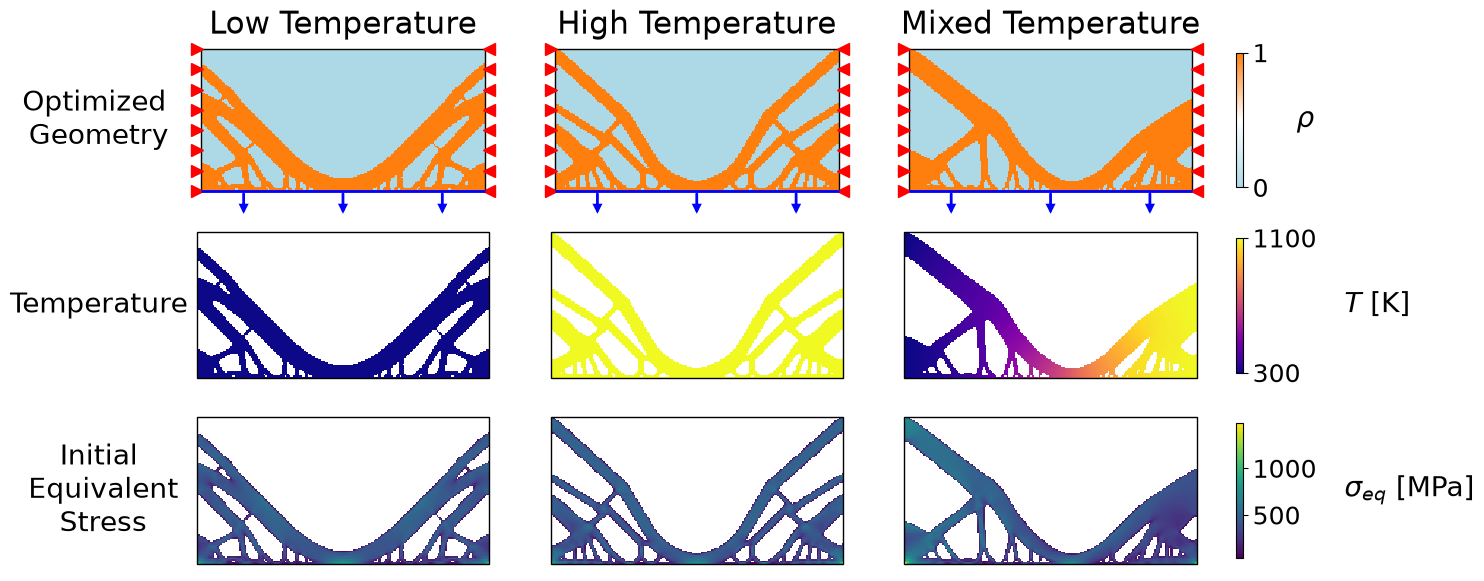

In [2]:
case_names = ["cold", "hot", "cold_hot"]
titles = ["Low Temperature", "High Temperature", "Mixed Temperature"]
cases = [load_case(name) for name in case_names]

# Shared stress scale across the row
stress_bounds = [solid_bounds(case["design"], case["vm_sig_0"]) for case in cases]
sig_lo = min(lo for lo, _ in stress_bounds)
sig_hi = max(hi for _, hi in stress_bounds)

fig, axes = plt.subplots(3, 3, figsize=(16, 7))
for j, (title, case) in enumerate(zip(titles, cases)):
    design = case["design"]
    c_geom = plot_field(axes[0, j], design, design.binary, cmap=specimen_cmap, vmin=0.0, vmax=1.0)
    draw_bcs(axes[0, j], design)
    c_temp = plot_field(axes[1, j], design, case["cell_temp"], cmap="plasma", mask=design.void_mask,
                        vmin=TEMP_MIN, vmax=TEMP_MAX)
    c_sig = plot_field(axes[2, j], design, case["vm_sig_0"], cmap="viridis", mask=design.void_mask,
                       vmin=sig_lo, vmax=sig_hi)
    axes[0, j].set_title(title, fontsize=TITLE_FS)

fig.subplots_adjust(wspace=0.1, hspace=0.1)

# One shared colorbar per row
colorbar_kwargs = dict(shrink=0.8, pad=0.02)
label_kwargs = dict(fontsize=CBAR_LABEL_FS, rotation=0, labelpad=20, va="center", ha="left")

cb_geom = fig.colorbar(c_geom, ax=axes[0, :], ticks=[0.0, 1.0], **colorbar_kwargs)
cb_geom.set_label(r"$\rho$", **label_kwargs)
cb_geom.set_ticklabels(["0", "1"])
cb_geom.ax.tick_params(labelsize=CBAR_TICK_FS)

cb_temp = fig.colorbar(c_temp, ax=axes[1, :], ticks=[TEMP_MIN, TEMP_MAX], **colorbar_kwargs)
cb_temp.set_label(r"$T$ [K]", **label_kwargs)
cb_temp.set_ticklabels(["300", "1100"])
cb_temp.ax.tick_params(labelsize=CBAR_TICK_FS)

cb_sig = fig.colorbar(c_sig, ax=axes[2, :], **colorbar_kwargs)
cb_sig.set_label(r"$\sigma_{eq}$ [MPa]", **label_kwargs)
cb_sig.ax.tick_params(labelsize=CBAR_TICK_FS)

label_rows(axes[:, 0], ["Optimized \nGeometry", "Temperature", "Initial\n Equivalent\n Stress"])

fig.savefig(FIGURES / "thermal_creep_shared_cbar.pdf", bbox_inches="tight")
plt.show()